# Real Data -- Combined vs. Containment-Split Comparison

Compares the combined 2-sample fit (`RealData`) against the containment-split 4-sample simultaneous fit (`RealData_Containment`), both on real Run 2 10% data (2.36124e19 POT). Self-contained: reads directly from both ROOT files with `uproot`, no dependency on the per-notebook plotting scripts, so it works regardless of which order you ran the two source notebooks in.

**What this does NOT do:** re-derive per-sample chi2 -- that still depends on the unverified/verified `cov_bin_range` conventions documented in each source notebook. This notebook only compares the two fits' final products: extracted cross-section, template parameters, and total fit chi2/ndf (read directly from `FitterEngine`, not recomputed).

In [5]:
import uproot
import numpy as np
import matplotlib.pyplot as plt

try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

combined_fit_path = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData/real_dpT.root'
combined_xs_path  = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/XSection/dpT/RealData/real_XSec_dpT.root'
cont_fit_path     = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root'
cont_xs_path      = '/data/XSection/dpT/RealData_Containment/real_containment_XSec_dpT_old.root'


## Cross-Section Overlay

Both extractions are on the same 7 truth bins (medulla-optimized combined binning), so a direct bin-by-bin overlay is meaningful.

/var/folders/hn/gg8vh0yd4j1382jb74b5wr780000gn/T/ipykernel_73979/2106280698.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Bin-by-bin cross section (x1e-37):
  0.068 GeV/c:  combined =   0.8969   containment =   0.9857   ratio = 1.099
  0.191 GeV/c:  combined =   1.1464   containment =   1.1950   ratio = 1.042
  0.299 GeV/c:  combined =   0.7569   containment =   0.7849   ratio = 1.037
  0.408 GeV/c:  combined =   0.6997   containment =   0.5664   ratio = 0.809
  0.531 GeV/c:  combined =   0.4537   containment =   0.4203   ratio = 0.926
  0.699 GeV/c:  combined =   0.2617   containment =   0.2013   ratio = 0.769


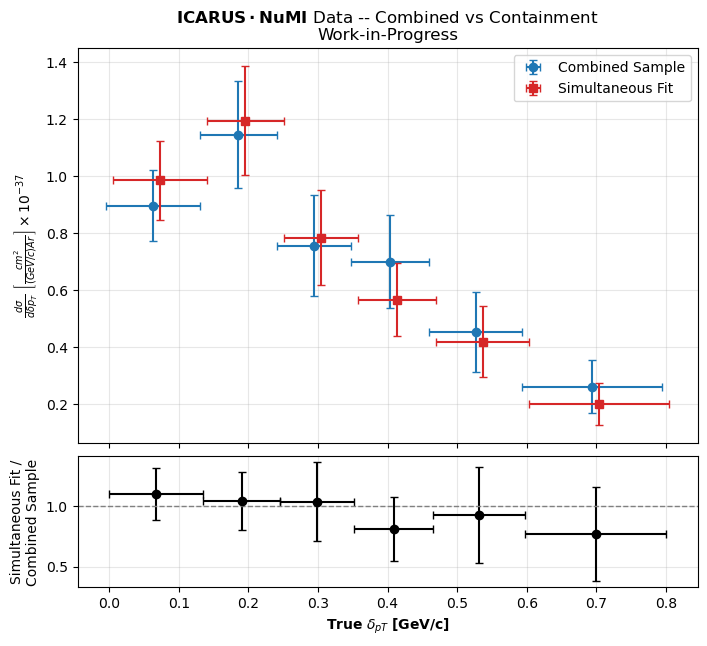

In [6]:
bin_edges_gev = np.array([0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8])
bin_centers = 0.5 * (bin_edges_gev[:-1] + bin_edges_gev[1:])
bin_half_widths = 0.5 * (bin_edges_gev[1:] - bin_edges_gev[:-1])

def read_xsec(path):
    with uproot.open(path) as f:
        h = f['calcXsec/histograms/True_dpT_XS_TH1D;1']
        values, edges = h.to_numpy()
        errors = h.errors()
    return values, errors

xs_combined, err_combined = read_xsec(combined_xs_path)
xs_cont, err_cont = read_xsec(cont_xs_path)

# Truncate/align to the 6 finite bins (drop overflow if present in the histogram)
n_bins = len(bin_centers)
xs_combined, err_combined = xs_combined[:n_bins], err_combined[:n_bins]
xs_cont, err_cont = xs_cont[:n_bins], err_cont[:n_bins]

scale = 1e40

fig, (ax_main, ax_ratio) = plt.subplots(
    2, 1, figsize=(8, 7), sharex=True,
    gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.05}
)

ax_main.errorbar(bin_centers - 0.005, xs_combined * scale, yerr=err_combined * scale,
                  xerr=bin_half_widths, fmt='o', color='tab:blue', label='Combined Sample', capsize=3)
ax_main.errorbar(bin_centers + 0.005, xs_cont * scale, yerr=err_cont * scale,
                  xerr=bin_half_widths, fmt='s', color='tab:red', label='Simultaneous Fit', capsize=3)
ax_main.set_ylabel(r'$\frac{d\sigma}{d\delta p_T}$ $\left[\frac{cm^2}{(GeV/c)Ar}\right] \times 10^{-37}$')
ax_main.set_title(r'$\bf{ICARUS \cdot NuMI}$ Data -- Combined vs Containment' + '\nWork-in-Progress')
ax_main.legend()
ax_main.grid(alpha=0.3)

ratio = xs_cont / xs_combined
ratio_err = ratio * np.sqrt((err_cont / xs_cont)**2 + (err_combined / xs_combined)**2)
ax_ratio.errorbar(bin_centers, ratio, yerr=ratio_err, xerr=bin_half_widths, fmt='o', color='black', capsize=3)
ax_ratio.axhline(1.0, color='gray', linestyle='--', linewidth=1)
ax_ratio.set_ylabel('Simultaneous Fit /\nCombined Sample')
ax_ratio.set_xlabel(r'$\mathbf{True}$ $\delta_{pT}$ $\mathbf{[GeV/c]}$')
ax_ratio.grid(alpha=0.3)

plt.tight_layout()
save_fig(fig, r'../Plots/dpT/Comparison', 'xsec_combined_vs_containment')

print('Bin-by-bin cross section (x1e-37):')
for c, xc, xcont in zip(bin_centers, xs_combined * scale, xs_cont * scale):
    print(f'  {c:.3f} GeV/c:  combined = {xc:8.4f}   containment = {xcont:8.4f}   ratio = {xcont/xc:.3f}')

## Template Parameter Overlay

Both fits use the same 7 truth-bin template parameters (dimensionless, expected to sit near 1.0). Comparing the post-fit pulls directly shows whether the extra reco-level shape information from the containment split changes what the fit infers about the true dpT spectrum.

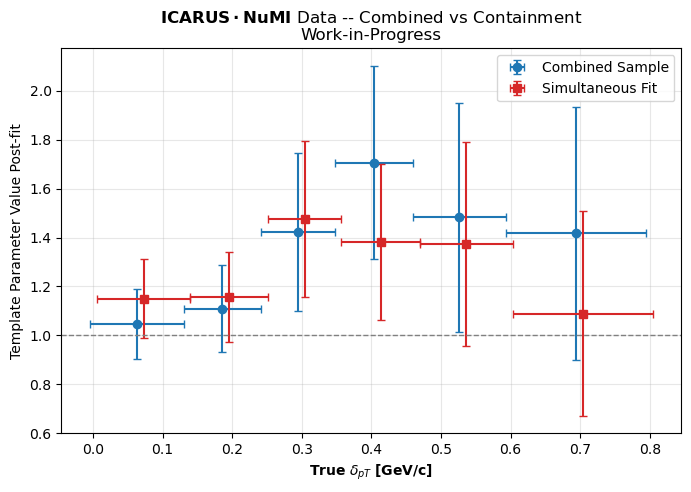

In [7]:
def read_template_params(path):
    with uproot.open(path) as f:
        h = f['FitterEngine/postFit/Hesse/errors/Template Parameter true_dpT_lp_genie/values/postFitErrors_TH1D;1']
        values, edges = h.to_numpy()
        errors = h.errors()
    return values, errors

tp_combined, tperr_combined = read_template_params(combined_fit_path)
tp_cont, tperr_cont = read_template_params(cont_fit_path)

n_bins = len(bin_centers)
tp_combined, tperr_combined = tp_combined[:n_bins], tperr_combined[:n_bins]
tp_cont, tperr_cont = tp_cont[:n_bins], tperr_cont[:n_bins]

fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.errorbar(bin_centers - 0.005, tp_combined, yerr=tperr_combined, xerr=bin_half_widths,
             fmt='o', color='tab:blue', label='Combined Sample', capsize=3)
ax2.errorbar(bin_centers + 0.005, tp_cont, yerr=tperr_cont, xerr=bin_half_widths,
             fmt='s', color='tab:red', label='Simultaneous Fit', capsize=3)
ax2.axhline(1.0, color='gray', linestyle='--', linewidth=1)
ax2.set_xlabel(r'$\mathbf{True}$ $\delta_{pT}$ $\mathbf{[GeV/c]}$')
ax2.set_ylabel('Template Parameter Value Post-fit')
ax2.set_title(r'$\bf{ICARUS \cdot NuMI}$ Data -- Combined vs Containment' + '\nWork-in-Progress')
ax2.legend()
ax2.grid(alpha=0.3)

save_fig(fig2, r'../Plots/dpT/Comparison', 'template_params_combined_vs_containment')

## Total Fit Chi2/ndf

Read directly from `FitterEngine/postFit/llhState_TNamed` -- the total -2lnL GUNDAM itself reports for each fit, not a recomputation. ndof differs between the two fits (combined: 2 samples on 13-row shared binning; containment: 4 samples, 21-row contained + 11-row exiting), so compare chi2/ndf, not raw chi2.

In [9]:
def read_llh_state(path):
    with uproot.open(path) as f:
        try:
            llh_named = f['FitterEngine/postFit/llhState_TNamed']
            return llh_named.member('fTitle') if hasattr(llh_named, 'member') else str(llh_named)
        except KeyError:
            return None

for label, path in [('Combined Sample', combined_fit_path), ('Simultaneous Fit', cont_fit_path)]:
    print(f'--- {label} ---')
    llh = read_llh_state(path)
    if llh is not None:
        print(llh)
    else:
        print('  llhState_TNamed not found at expected path -- check the object path in the ROOT file directly with f.keys() / f.classnames() and update the path above.')
    print()

--- Combined Sample ---
Total likelihood = 30.1875
Stat likelihood = 27.7912 = sum of: { 
  selection_reco_dpT: 3.00368, 
  sideband_reco_dpT: 24.7875
}
Penalty likelihood = 2.39636 = sum of: { 
  Template Parameter true_dpT_lp_genie: 0, 
  Cross section Systematics: 2.30963, 
  Multisigma Flux Systematics: 0.0827056, 
  Detector Systematics: 0.00402206
}

--- Simultaneous Fit ---
Total likelihood = 113.781
Stat likelihood = 107.683 = sum of: { 
  selection_reco_dpT_contained: 20.8692, 
  selection_reco_dpT_exiting: 15.5205, 
  sideband_reco_dpT_contained: 36.1365, 
  sideband_reco_dpT_exiting: 35.1571
}
Penalty likelihood = 6.09797 = sum of: { 
  Template Parameter true_dpT_lp_genie: 0, 
  Cross section Systematics: 4.74274, 
  Multisigma Flux Systematics: 0.676045, 
  Detector Systematics: 0.679188
}

